# ES 5201 Homework 3

In [ ]:
%pip install obspy -q

In [ ]:
%pip install geopy -q

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from obspy import UTCDateTime
from obspy.clients.fdsn import Client
from obspy import read, read_inventory
from obspy.taup import TauPyModel
from obspy.geodetics.base import gps2dist_azimuth
from obspy.geodetics import locations2degrees

from geopy.distance import distance
from geopy.distance import geodesic

## 1 a)
Vertical components waveforms for each station and determine P wave by manually picking it.

In [ ]:
# https://earthquake.usgs.gov/earthquakes/eventpage/se60597816/executive
client_events = Client("https://earthquake.usgs.gov")

events = client_events.get_events(
    starttime=UTCDateTime("2025-02-03T21:00:00"),
    endtime=UTCDateTime("2025-02-04T21:15:00"),
    minmagnitude=3.0,
    maxmagnitude=3.2,
)

print(events.__str__(print_all=True))

15 Event(s) in Catalog:
2025-02-04T20:33:03.147000Z | +53.342, -163.906 | 3.1  ml | manual
2025-02-04T20:19:10.095000Z | +53.268, -163.929 | 3.0  ml | manual
2025-02-04T20:10:51.739000Z | +40.423, -126.877 | 3.2  ml | manual
2025-02-04T18:05:15.553000Z | +52.677, -173.391 | 3.2  ml | manual
2025-02-04T15:10:34.230000Z | +60.184, -152.251 | 3.0  ml | manual
2025-02-04T12:43:45.646000Z | +65.522, -168.415 | 3.0  ml | manual
2025-02-04T09:39:08.651000Z | +52.219, -170.305 | 3.1  ml | manual
2025-02-04T08:40:59.360000Z | +52.272, -170.559 | 3.2  ml | manual
2025-02-04T06:01:40.230000Z | +41.560, -109.887 | 3.12 ml | manual
2025-02-04T04:13:34.475000Z | +51.401, +179.891 | 3.1  ml | manual
2025-02-04T02:34:25.106000Z | +65.430, -168.245 | 3.1  ml | manual
2025-02-03T23:42:07.521000Z | +53.556, -165.785 | 3.2  ml | manual
2025-02-03T23:28:49.783000Z | +53.205, -159.835 | 3.0  ml | manual
2025-02-03T21:57:57.867000Z | +65.471, -168.393 | 3.1  ml | manual
2025-02-03T21:04:52.850000Z | +38.920,

In [ ]:
client = Client("EARTHSCOPE")
print(client)

FDSN Webservice Client (base url: https://service.earthscope.org)
Available Services: 'dataselect' (v1.1.82), 'station' (v1.1.58)

Use e.g. client.help('dataselect') for the
parameter description of the individual services
or client.help() for parameter description of
all webservices.


In [ ]:
# see lecture 2 github notes https://github.com/crowell97/ES5201/blob/main/ES5201_Lecture2.ipynb
event = events[14]
origin = event.preferred_origin() or event.origins[14]
magnitude = event.preferred_magnitude() or event.magnitudes[14]

print(f"{origin.time}  M{magnitude.mag:.1f}  "
      f"lat={origin.latitude:.2f}, lon={origin.longitude:.2f}, depth={origin.depth/1000:.1f} km")

2025-02-03T21:04:52.850000Z  M3.1  lat=38.92, lon=-82.58, depth=25.9 km


In [ ]:
def fetch_event_waveform(client, network, station, location, channel,
                          event_time, pre_s=0, post_s=90, output="VEL",
                          freqmin=0.02, freqmax=10.0, corners=4, zerophase=True):
    t_start, t_end = event_time - pre_s, event_time + post_s

    inv = client.get_stations(network=network, station=station, channel=channel,
                               location=location, starttime=t_start, endtime=t_end,
                               level="response")
    st = client.get_waveforms(network=network, station=station, location=location,
                               channel=channel, starttime=t_start, endtime=t_end)
    st.remove_response(inventory=inv, output=output)

    if freqmin is not None and freqmax is not None:
        st.filter("bandpass", freqmin=freqmin, freqmax=freqmax,
                   corners=corners, zerophase=zerophase)

    return st, inv

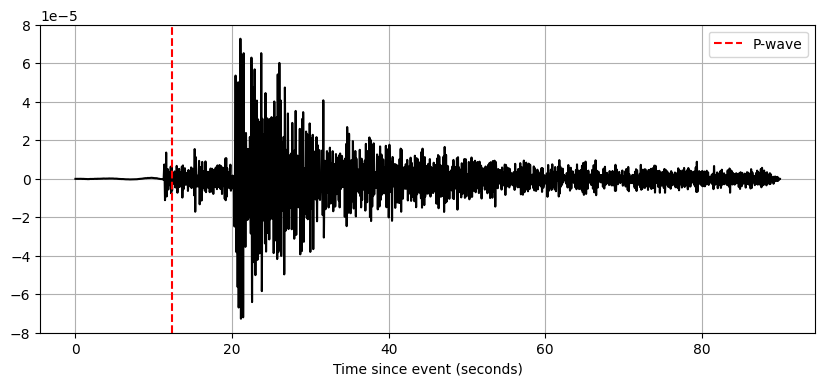

In [ ]:
# N4.Q51A https://ds.iris.edu/mda/N4/Q51A/
stQ51A, invQ51A = fetch_event_waveform(client, "N4", "Q51A", "00", "HHZ", origin.time, output="VEL")

trQ51A=stQ51A[0]

plt.figure(figsize=(10, 4))
plt.plot(trQ51A.times(), trQ51A.data, color="black")
#plt.axvline(30, color="black", linestyle="-", label="Event Origin")
plt.axvline(12.3, color="red", linestyle="--", label="P-wave")
plt.xlabel("Time since event (seconds)")
plt.grid(True)
plt.legend()
plt.show()

#stQ51A.plot()

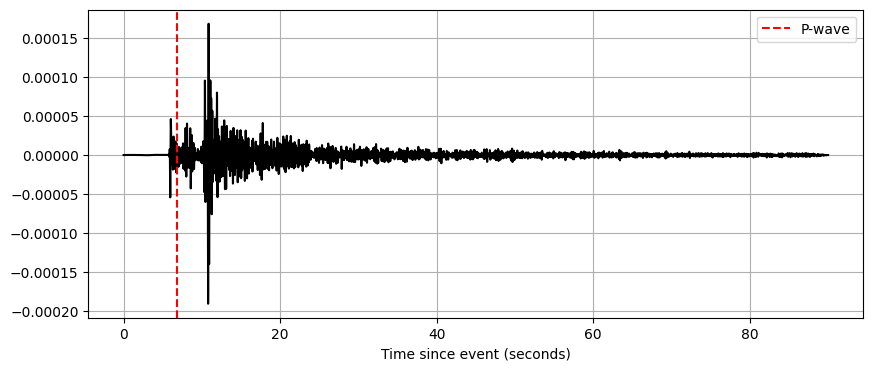

In [ ]:
# N4.Q52A https://ds.iris.edu/mda/N4/Q52A/
stQ52A, invQ52A = fetch_event_waveform(client, "N4", "Q52A", "00", "HHZ", origin.time, output="VEL")

trQ52A=stQ52A[0]

plt.figure(figsize=(10, 4))
plt.plot(trQ52A.times(), trQ52A.data, color="black")
#plt.axvline(30, color="black", linestyle="-", label="Event Origin")
plt.axvline(6.8, color="red", linestyle="--", label="P-wave")
plt.xlabel("Time since event (seconds)")
plt.grid(True)
plt.legend()
plt.show()

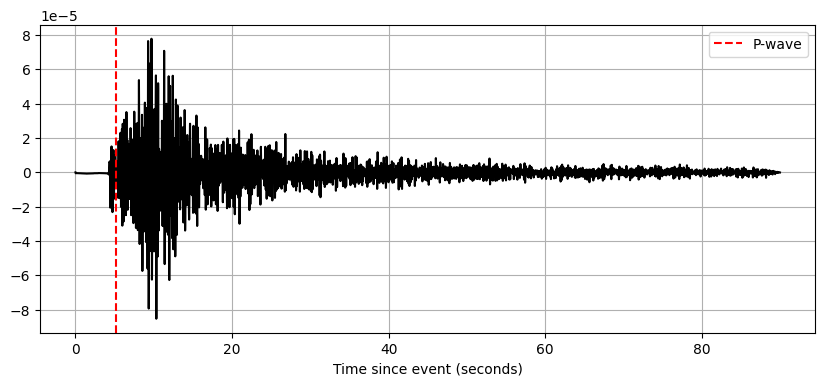

In [ ]:
# OH.CHWO https://ds.iris.edu/mda/OH/CHWO/
stCHWO, invCHWO = fetch_event_waveform(client, "OH", "CHWO", "--", "HHZ", origin.time, output="VEL")

trCHWO=stCHWO[0]

plt.figure(figsize=(10, 4))
plt.plot(trCHWO.times(), trCHWO.data, color="black")
#plt.axvline(30, color="black", linestyle="-", label="Event Origin")
plt.axvline(5.2, color="red", linestyle="--", label="P-wave")
plt.xlabel("Time since event (seconds)")
plt.grid(True)
plt.legend()
plt.show()

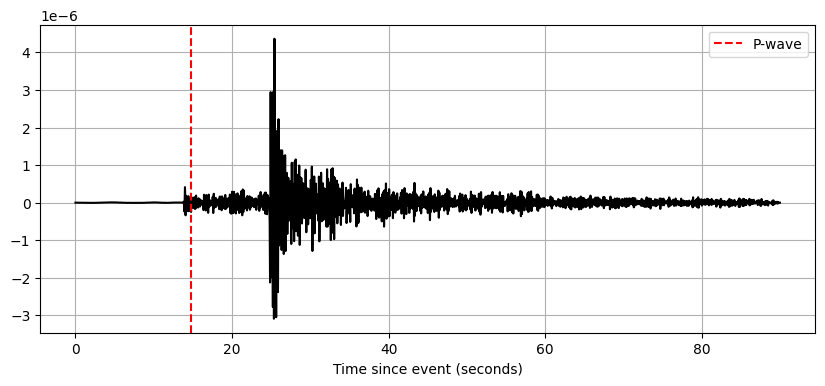

In [ ]:
# OH.CPOH https://ds.iris.edu/mda/OH/CPOH/
stCPOH, invCPOH = fetch_event_waveform(client, "OH", "CPOH", "--", "HHZ", origin.time, output="VEL")

trCPOH=stCPOH[0]

plt.figure(figsize=(10, 4))
plt.plot(trCPOH.times(), trCPOH.data, color="black")
#plt.axvline(30, color="black", linestyle="-", label="Event Origin")
plt.axvline(14.8, color="red", linestyle="--", label="P-wave")
plt.xlabel("Time since event (seconds)")
plt.grid(True)
plt.legend()
plt.show()

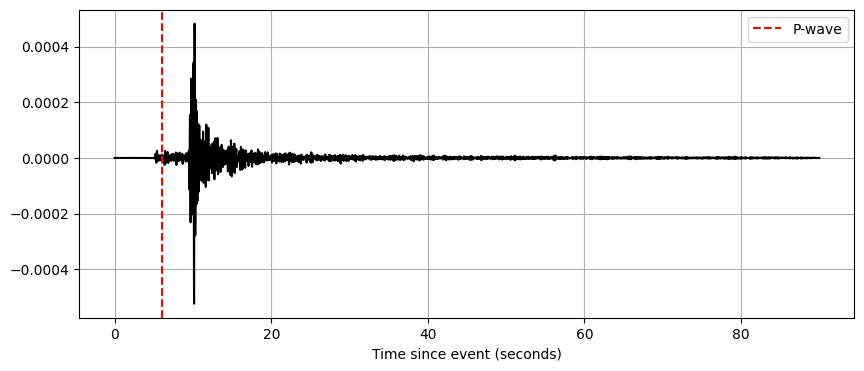

In [ ]:
# OH.DSFO https://ds.iris.edu/mda/OH/DSFO/
stDSFO, invDSFO = fetch_event_waveform(client, "OH", "DSFO", "10", "HHZ", origin.time, output="VEL")

trDSFO=stDSFO[0]

plt.figure(figsize=(10, 4))
plt.plot(trDSFO.times(), trDSFO.data, color="black")
#plt.axvline(30, color="black", linestyle="-", label="Event Origin")
plt.axvline(6, color="red", linestyle="--", label="P-wave")
plt.xlabel("Time since event (seconds)")
plt.grid(True)
plt.legend()
plt.show()

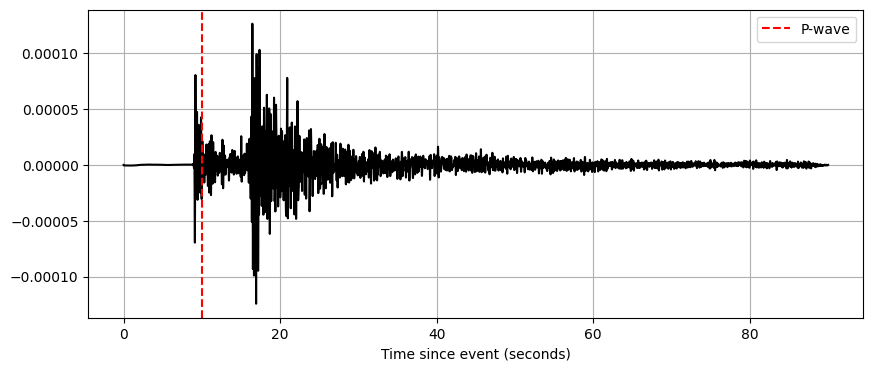

In [ ]:
# OH.SSF2 https://ds.iris.edu/mda/OH/SSF2/
stSSF2, invSSF2 = fetch_event_waveform(client, "OH", "SSF2", "--", "HHZ", origin.time, output="VEL")

trSSF2=stSSF2[0]

plt.figure(figsize=(10, 4))
plt.plot(trSSF2.times(), trSSF2.data, color="black")
#plt.axvline(30, color="black", linestyle="-", label="Event Origin")
plt.axvline(10, color="red", linestyle="--", label="P-wave")
plt.xlabel("Time since event (seconds)")
plt.grid(True)
plt.legend()
plt.show()

## 1 b)
Given published location of earthquake, find a single P-wave velocity that best fits the data.

In [ ]:
eq = (38.920, -82.581)
Q51Ab = (39.0026, -83.3456)
Q52Ab = (38.9622, -82.2669)
CHWO = (38.93602, -82.526105)
CPOH = (38.8401, -83.5776)
DSFO = (38.690952, -82.616898)
SSF2 = (38.6886, -83.1276)

event_depth = 25.9 #km

pQ51A=12.3
pQ52A=6.8
pCHWO=5.2
pCPOH=14.8
pDSFO=6
pSSF2=10

distance1 = distance(eq, Q51Ab).km
hypo1 = np.sqrt(distance1**2 + event_depth**2)
vel1 = hypo1/pQ51A

distance2 = distance(eq, Q52Ab).km
hypo2 = np.sqrt(distance2**2 + event_depth**2)
vel2 = hypo2/pQ52A

distance3 = distance(eq, CHWO).km
hypo3 = np.sqrt(distance3**2 + event_depth**2)
vel3 = hypo3/pCHWO

distance4 = distance(eq, CPOH).km
hypo4 = np.sqrt(distance4**2 + event_depth**2)
vel4 = hypo4/pCPOH

distance5 = distance(eq, DSFO).km
hypo5 = np.sqrt(distance5**2 + event_depth**2)
vel5 = hypo5/pDSFO

distance6 = distance(eq, SSF2).km
hypo6 = np.sqrt(distance6**2 + event_depth**2)
vel6 = hypo6/pSSF2

print(vel1)
print(vel2)
print(vel3)
print(vel4)
print(vel5)
print(vel6)

print("average velocity: ", (vel1+vel2+vel3+vel4+vel5+vel6)/6)


5.832539726999132
5.569498062027568
5.075728667058567
6.128850460543145
6.071487956475713
5.98751895426623
average velocity:  5.777603971228392


## 1 c
determine the optimal L2-
norm location for the earthquake and origin time difference, plotting the misfit space

In [43]:
model = TauPyModel(model="ak135")

true_lat = 38.920
true_lon = -82.581
true_depth = 25.9 #km
event_time = UTCDateTime("2025-02-03T21:04:52")

pQ51A=12.3
pQ52A=6.8
pCHWO=5.2
pCPOH=14.8
pDSFO=6
pSSF2=10

Q51Ac = (39.0026, -83.3456, event_time + pQ51A)
Q52Ac = (38.9622, -82.2669, event_time + pQ52A)
CHWOc = (38.93602, -82.526105, event_time + pCHWO)
CPOHc = (38.8401, -83.5776, event_time + pCPOH)
DSFOc = (38.690952, -82.616898, event_time + pDSFO)
SSF2c = (38.6886, -83.1276, event_time + pSSF2)

# Storing as a list instead of a set because UTCDateTime is unhashable
stations = [
    Q51Ac,
    Q52Ac,
    CHWOc,
    CPOHc,
    DSFOc,
    SSF2c
]

v = 5.777603971228392 #from 1b avg vel

In [44]:
# grid
lat_range = np.arange(true_lat - 0.5, true_lat + 0.5, 0.01)
lon_range = np.arange(true_lon - 0.5, true_lon + 0.5, 0.01)

grid_lat, grid_lon = np.meshgrid(lat_range, lon_range)

misfit_grid = np.zeros((len(lat_range), len(lon_range)))
origin_grid = np.zeros((len(lat_range), len(lon_range)))

In [47]:
for i, lat in enumerate(lat_range):
    for j, lon in enumerate(lon_range):
        residuals = []
        origin_time_est = []

        # Corrected: iterating directly over the list of tuples instead of calling .items()
        for (sta_lat, sta_lon, t) in stations:
            epidist_deg = locations2degrees(lat, lon, sta_lat, sta_lon)

            arrivals = model.get_travel_times(source_depth_in_km=true_depth,
                                              distance_in_degree=epidist_deg,
                                              phase_list=["p"])

            if arrivals:
                theo_time = event_time + arrivals[0].time
                residuals.append((t - theo_time) ** 2)
                origin_time_est.append(t - arrivals[0].time)

        if residuals:
            misfit_grid[i, j] = np.sqrt(np.sum(residuals))

            if origin_time_est:
                origin_time_est_numeric = [ot.timestamp for ot in origin_time_est]
                est_origin_time_numeric = np.mean(origin_time_est_numeric)
                est_origin_time = UTCDateTime(est_origin_time_numeric)
                origin_grid[i, j] = est_origin_time - event_time
        else:
            misfit_grid[i, j] = np.nan
            origin_grid[i, j] = np.nan

In [48]:
calc_idx = np.where(np.min(misfit_grid)==misfit_grid)
print(calc_idx)

(array([47]), array([50]))


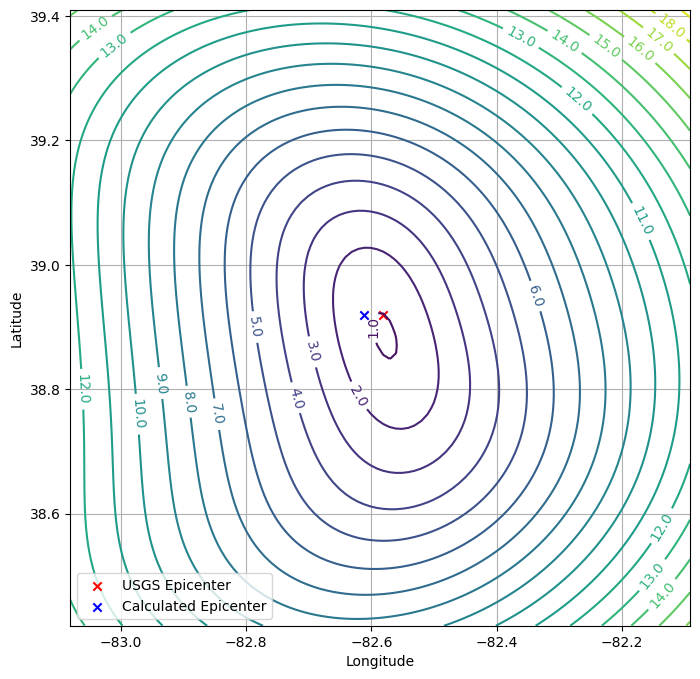

USGS Epicenter: Latitude = 38.92, Longitude = -82.581
Calculated Epicenter: Latitude = [38.92], Longitude = [-82.611]
Origin Time Difference: 0.30 seconds


In [51]:
calc_lat = grid_lat[calc_idx]
calc_lon = grid_lon[calc_idx]
calc_origin_time_diff = origin_grid[calc_idx].item()

# Plot the misfit space
plt.figure(figsize=(8, 8))
contour = plt.contour(lon_range, lat_range, misfit_grid, levels=20, cmap='viridis')
plt.clabel(contour, inline=True, fontsize=10, fmt='%1.1f')  # Add labels to contour lines
plt.scatter(true_lon, true_lat, c='r', marker="x", label='USGS Epicenter')
plt.scatter(calc_lon, calc_lat, c='b', marker="x", label='Calculated Epicenter')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.grid()
plt.show()

print(f"USGS Epicenter: Latitude = {true_lat}, Longitude = {true_lon}")
print(f"Calculated Epicenter: Latitude = {calc_lat}, Longitude = {calc_lon}")
print(f"Origin Time Difference: {calc_origin_time_diff:.2f} seconds")


## 1 d)
how many seconds
of warning would we receive in Mendenhall Laboratory using taup theoretical ‘s’ travel
times?

In [37]:
# Load a standard Earth model
model = TauPyModel(model="ak135")

# Earthquake location (Oak Hill, OH)
eq_lat = 38.920
eq_lon = -82.581
depth = 25.9

# Station locations (Latitude, Longitude)
stationsd = {
    "Q51A": (39.026, -83.3456),
    "Q52A": (38.9622, -82.266899),
    "CHWO": (38.93602, -82.526105),
    "CPOH": (38.8401, -83.5776),
    "DSFO": (38.690952, -82.616898),
    "SSF2": (38.6886, -83.1276)
}

ptime = {
    "Q51A": (12.1),
    "Q52A": (6.8),
    "CHWO": (5.2),
    "CPOH": (14.8),
    "DSFO": (6.1),
    "SSF2": (10.0)
}

mendenhall_lat = 39.99823
mendenhall_lon = -83.01132

In [40]:
# travel times
def compute_travel_time(lat, lon, phase):
  distance_deg = locations2degrees(eq_lat, eq_lon, lat, lon)
  arrivals = model.get_travel_times(source_depth_in_km=depth,
                                    distance_in_degree=distance_deg,
                                    phase_list=[phase])
  return arrivals[0].time if arrivals else None

sorted_sta = sorted(ptime, key=ptime.get)

#fourth closest station from epicenter
four_sta = sorted_sta[3]
four_sta_p = ptime[four_sta]

#print(four_sta)
#print(four_sta_p)

mag_comp = four_sta_p + 3

#swavetravel
s_mendenhall = compute_travel_time(mendenhall_lat, mendenhall_lon, "S")

#warning time
warning = s_mendenhall - mag_comp

print(s_mendenhall)
print(warning)

34.75272829256863
21.752728292568627
